In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

In [2]:
rfm_scaled = pd.read_csv(
    "../data/processed/customer_rfm_scaled.csv",
    index_col="CustomerID"
)

rfm = pd.read_csv(
    "../data/processed/customer_segments.csv",
    index_col="CustomerID"
)

print("Scaled data:", rfm_scaled.shape)
print("Segment data:", rfm.shape)

Scaled data: (4338, 3)
Segment data: (4338, 4)


In [3]:
X = rfm_scaled[["Recency", "Frequency", "Monetary"]]
labels = rfm["Cluster"]

silhouette = silhouette_score(X, labels)
davies = davies_bouldin_score(X, labels)
calinski = calinski_harabasz_score(X, labels)

print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Score:", round(davies, 4))
print("Calinski-Harabasz Score:", round(calinski, 4))

Silhouette Score: 0.3375
Davies-Bouldin Score: 1.0086
Calinski-Harabasz Score: 3328.3383


In [4]:
cluster_analysis = rfm.groupby("Cluster").agg(
    Customer_Count=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

display(cluster_analysis)

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue
Cluster,,,,,
0,713,12.17,13.75,8088.02,5766757.07
1,1622,181.51,1.32,341.00,553099.77
2,837,17.70,2.19,557.32,466479.03
3,1166,71.64,4.08,1801.78,2100873.02


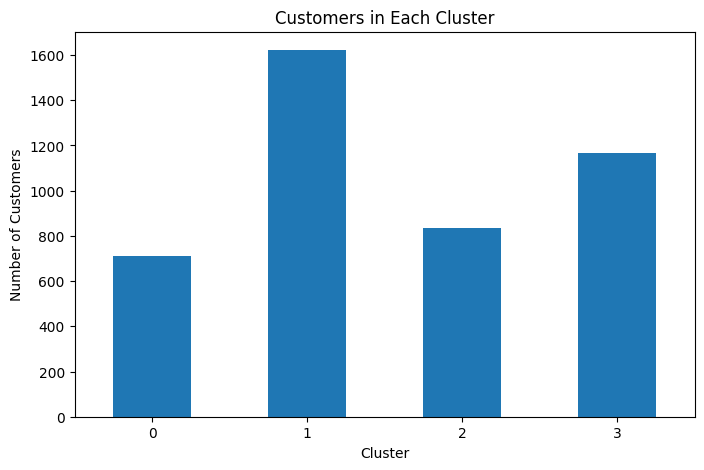

In [5]:
cluster_analysis["Customer_Count"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

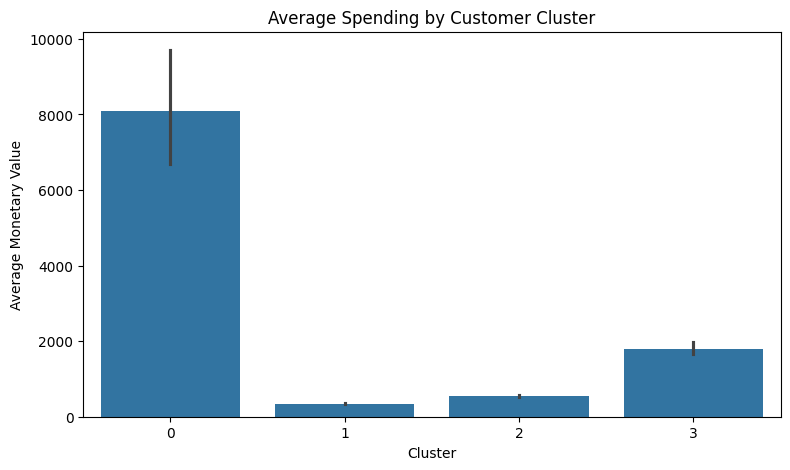

In [6]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=rfm,
    x="Cluster",
    y="Monetary",
    estimator="mean"
)

plt.title("Average Spending by Customer Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Monetary Value")
plt.show()

In [7]:
segment_names = {
    0: "Segment 0",
    1: "Segment 1",
    2: "Segment 2",
    3: "Segment 3"
}

rfm["Customer_Segment"] = (
    rfm["Cluster"].map(segment_names)
)

display(rfm.head())

,Recency,Frequency,Monetary,Cluster,Customer_Segment
CustomerID,,,,,
12346,326,1,77183.60,3,Segment 3
12347,2,7,4310.00,0,Segment 0
12348,75,4,1797.24,3,Segment 3
12349,19,1,1757.55,2,Segment 2
12350,310,1,334.40,1,Segment 1


In [8]:
import os

os.makedirs("../visualizations", exist_ok=True)

cluster_analysis.to_csv(
    "../visualizations/cluster_business_report.csv"
)

rfm.to_csv(
    "../data/processed/final_customer_segments.csv"
)

print("Evaluation and business report saved!")

Evaluation and business report saved!
